In [ ]:
import pandas as pd
import numpy as np

from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer

RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")

cv_df = pd.read_csv(PROCESSED_DIR / "cv_processed.csv")
job_df = pd.read_csv(PROCESSED_DIR / "job_processed.csv")
matches_df = pd.read_csv(RAW_DIR / "matches.csv")

print("CV:", cv_df.shape)
print("Jobs:", job_df.shape)
print("Matches:", matches_df.shape)

CV: (9544, 8)
Jobs: (1167, 8)
Matches: (122560, 13)


In [2]:
documents = (
    cv_df["resume_text_clean"].fillna("").tolist()
    + job_df["job_text_clean"].fillna("").tolist()
)

vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    max_features=10000
)

tfidf_matrix = vectorizer.fit_transform(documents)

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))

TF-IDF matrix shape: (10711, 10000)
Vocabulary size: 10000


In [3]:
cv_count = len(cv_df)

cv_tfidf = tfidf_matrix[:cv_count]
job_tfidf = tfidf_matrix[cv_count:]

print("CV TF-IDF:", cv_tfidf.shape)
print("Job TF-IDF:", job_tfidf.shape)

CV TF-IDF: (9544, 10000)
Job TF-IDF: (1167, 10000)


In [4]:
sample_matches = matches_df.sample(
    n=2000,
    random_state=42
).copy()

cv_index = pd.Series(
    np.arange(len(cv_df)),
    index=cv_df["candidate_id"]
)

job_index = pd.Series(
    np.arange(len(job_df)),
    index=job_df["job_id"]
)

cv_rows = sample_matches["candidate_id"].map(cv_index).to_numpy()
job_rows = sample_matches["job_id"].map(job_index).to_numpy()

print("Sample size:", len(sample_matches))
print("Missing CV mappings:", pd.isna(cv_rows).sum())
print("Missing Job mappings:", pd.isna(job_rows).sum())

Sample size: 2000
Missing CV mappings: 0
Missing Job mappings: 0


In [5]:
pairwise_scores = cv_tfidf[cv_rows].multiply(
    job_tfidf[job_rows]
).sum(axis=1)

sample_matches["tfidf_score"] = np.asarray(
    pairwise_scores
).ravel()

print(sample_matches[
    ["candidate_id", "job_id", "tfidf_score", "final_score"]
].head(10))

       candidate_id      job_id  tfidf_score  final_score
3903     cand_00302  3901981623     0.022707     0.569521
47008    cand_03670  3901393491     0.121963     0.660155
86999    cand_06785  3895849293     0.140188     0.444185
2532     cand_00200  3902329403     0.014958     0.608598
108479   cand_08451  3905350188     0.120324     0.618471
99856    cand_07798  3901800100     0.026279     0.610271
36832    cand_02853  3899930721     0.073440     0.601233
93509    cand_07281  3902864826     0.110768     0.556573
53892    cand_04189  3901949867     0.141667     0.605328
95103    cand_07403  3901959141     0.032053     0.570742


count    2000.000000
mean        0.061358
std         0.036291
min         0.002071
25%         0.034693
50%         0.053546
75%         0.079310
max         0.271941
Name: tfidf_score, dtype: float64


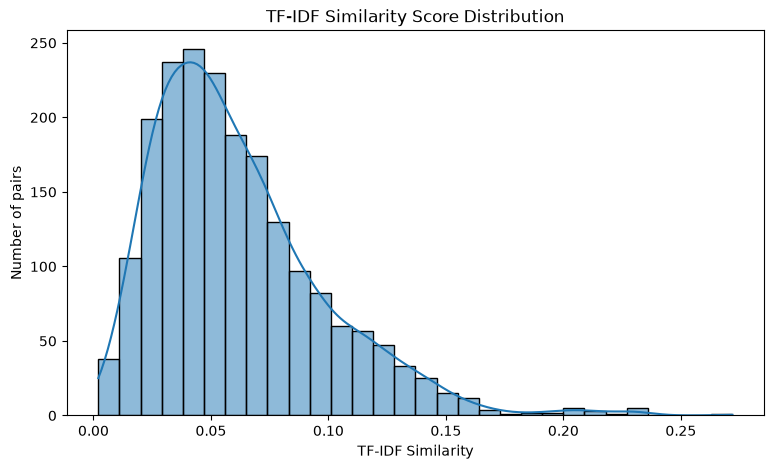

In [6]:
print(sample_matches["tfidf_score"].describe())

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.histplot(sample_matches["tfidf_score"], bins=30, kde=True)

plt.title("TF-IDF Similarity Score Distribution")
plt.xlabel("TF-IDF Similarity")
plt.ylabel("Number of pairs")

plt.show()

In [7]:
print("Correlation with reference final_score:")

print(
    sample_matches[
        ["tfidf_score", "final_score"]
    ].corr()
)

Correlation with reference final_score:
             tfidf_score  final_score
tfidf_score     1.000000     0.247139
final_score     0.247139     1.000000


In [8]:
print(
    sample_matches.groupby("label_strength")["tfidf_score"]
    .agg(["count", "mean", "min", "max"])
    .sort_values("mean", ascending=False)
)

                 count      mean       min       max
label_strength                                      
strong_positive      7  0.100783  0.032783  0.229579
medium_positive   1138  0.067988  0.004129  0.271941
weak_positive      855  0.052210  0.002071  0.216533


In [9]:
print(
    sample_matches.groupby("label_strength")[
        ["tfidf_score", "final_score"]
    ].mean()
)

                 tfidf_score  final_score
label_strength                           
medium_positive     0.067988     0.607249
strong_positive     0.100783     0.695838
weak_positive       0.052210     0.553418
